# 04 · Which 100 m cells the model learns from

**Question:** a 100 m cell holds about eleven 30 m Hansen pixels, and most cells with loss lose only part of their forest. Which cells should the risk model learn from as lost, and which as forest that stayed?

The platform answers the first question with a majority rule (`HansenShares.display_arrays`, 26 October 2026): a cell is forest while at least half of it is forest, and lost in the year it falls below half. Its areas come from the 30 m shares; this rule only gives the masks the risk model learns from and scores. Four rules are compared:

| Rule | Forest cells | Lost cells (training) |
|---|---|---|
| Half the cell (platform) | At least half forest | Falls below half forest in the window |
| Any loss, half-forest cells | At least half forest | Loses any forest in the window |
| Any loss, any forest | Any forest | Loses any forest in the window |
| Weighted by the shares | Any forest | Cells drawn in proportion to the forest lost and kept in them: the same as drawing 30 m pixels |

The distances to prior and recent loss follow each rule's lost cells. The local loss rate (share of the forest lost within 5 km in the 3 years before) comes from the shares, the same for every rule.

All four rules train the same model, the improved model (16 predictors measured at the window's start, including the local loss rate and the distance to recent loss; notebook 05 tests them).

**How the rules are judged.** In each of the three windows, every rule trains the model on the loss of the calibration window (for example 2014–2016), with the predictors at its start. The model then ranks the forest standing at the start of the next window, and that ranking is checked against the next window's loss (for example 2017–2019), which no model saw. The check is the **AUC over the 30 m forest pixels**: the chance that a pixel lost in the test window ranks above one that stayed. Every rule is checked on the same pixels: each cell counts the forest it lost in the test window as lost and the forest it kept as kept, so no rule's own choice of cells decides the score. A rule is better if its AUC is higher in all three windows by more than the run-to-run noise (the spread over three seeds).

The code is `scripts/model.py`. Results are saved in `outputs/runs/`; set `RERUN = True` to compute them again (about 15 minutes per window).

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "scripts"))
import model as MM

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
RERUN = False
runs = [MM.cached(MM.split_name(s), lambda s=s: MM.run_split(s), rerun=RERUN) for s in MM.SPLITS]
LABELS = MM.RULES

## 1 · What each rule counts

For each calibration window: how many cells each rule counts as lost, their area as whole cells, and the 30 m loss inside them, against all 30 m loss of the window.

In [2]:
rows = []
for run in runs:
    for rule, r in run["rules"].items():
        rows.append({"Window": run["split"].split(" → ")[0], "Rule": LABELS[rule],
                     "Lost cells (thousand)": r["lost_cells"] / 1e3, "Kept forest cells (million)": r["kept_cells"] / 1e6,
                     "Lost cells' area (km²)": r["lost_cells_ha"] / 100,
                     "30 m loss inside them (km²)": r["loss_in_lost_cells_ha"] / 100,
                     "Share of the window's loss (%)": 100 * r["loss_in_lost_cells_ha"] / run["calibration_loss_ha"]})
counts = pd.DataFrame(rows).set_index(["Window", "Rule"])
counts.round(1).to_csv(OUT / "04_what_each_rule_counts.csv")
counts.round(1)

Lost cells (thousand)  \
Window    Rule                                                 
2014–2016 Half the cell (platform)                     521.2   
          Any loss, half-forest cells                 1520.8   
          Any loss, any forest                        1842.9   
          Weighted by the shares                      1842.9   
2017–2019 Half the cell (platform)                     681.9   
          Any loss, half-forest cells                 1505.5   
          Any loss, any forest                        1957.3   
          Weighted by the shares                      1957.3   
2019–2021 Half the cell (platform)                     630.8   
          Any loss, half-forest cells                 1378.3   
          Any loss, any forest                        1911.1   
          Weighted by the shares                      1911.1   

                                       Kept forest cells (million)  \
Window    Rule                                                       
2014–2016 Half the cell (platform)                             7.4   
          Any loss, half-forest cells                          6.4   
          Any loss, any forest                                10.4   
          Weighted by the shares                              12.1   
2017–2019 Half the cell (platform)                             6.7   
          Any loss, half-forest cells                          5.9   
          Any loss, any forest                                10.1   
          Weighted by the shares                              11.8   
2019–2021 Half the cell (platform)                             6.3   
          Any loss, half-forest cells                          5.6   
          Any loss, any forest                                10.0   
          Weighted by the shares                              11.6   

                                       Lost cells' area (km²)  \
Window    Rule                                                  
2014–2016 Half the cell (platform)                     5129.9   
          Any loss, half-forest cells                 14986.7   
          Any loss, any forest                        18153.8   
          Weighted by the shares                      18153.8   
2017–2019 Half the cell (platform)                     6714.3   
          Any loss, half-forest cells                 14838.4   
          Any loss, any forest                        19282.8   
          Weighted by the shares                      19282.8   
2019–2021 Half the cell (platform)                     6212.3   
          Any loss, half-forest cells                 13585.9   
          Any loss, any forest                        18828.4   
          Weighted by the shares                      18828.4   

                                       30 m loss inside them (km²)  \
Window    Rule                                                       
2014–2016 Half the cell (platform)                          3197.8   
          Any loss, half-forest cells                       4752.1   
          Any loss, any forest                              5123.0   
          Weighted by the shares                            5123.0   
2017–2019 Half the cell (platform)                          4212.6   
          Any loss, half-forest cells                       5516.4   
          Any loss, any forest                              6098.3   
          Weighted by the shares                            6098.3   
2019–2021 Half the cell (platform)                          3600.3   
          Any loss, half-forest cells                       4724.1   
          Any loss, any forest                              5417.3   
          Weighted by the shares                            5417.3   

                                       Share of the window's loss (%)  
Window    Rule                                                         
2014–2016 Half the cell (platform)                               62.4  
          Any loss, half-forest cells                

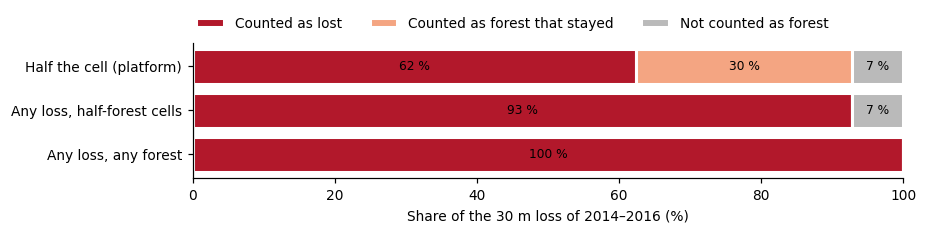

In [3]:
# Where the 30 m loss of 2014-2016 lies, for each rule: in cells it counts as lost, in cells it counts
# as forest that stayed, or in cells it does not count as forest at all.
t1, t2 = MM.SPLITS[0][:2]
f1, f2, lw = MM.forest_pct(t1), MM.forest_pct(t2), MM.loss_pct(t1, t2)
loss_ha = lw / 100 * MM.hansen()["area"]
half1 = f1 >= 50
where = {LABELS["half"]: (MM.lost("half", t1, t2), half1 & (f2 >= 50)),
         LABELS["any_half"]: (half1 & (lw > 0), np.zeros_like(half1)),
         LABELS["any"]: (lw > 0, np.zeros_like(half1))}
parts = pd.DataFrame({rule: {"Counted as lost": loss_ha[lost].sum(), "Counted as forest that stayed": loss_ha[kept].sum(),
                             "Not counted as forest": loss_ha[~lost & ~kept].sum()} for rule, (lost, kept) in where.items()}).T
parts = 100 * parts.div(parts.sum(axis=1), axis=0)
colors = ["#b2182b", "#f4a582", "#bababa"]
fig, ax = plt.subplots(figsize=(8.5, 2.2))
left = np.zeros(len(parts))
for column, color in zip(parts.columns, colors):
    ax.barh(parts.index, parts[column], left=left, color=color, edgecolor="white", linewidth=2, label=column)
    for y, (x0, w) in enumerate(zip(left, parts[column])):
        if w > 6:
            ax.text(x0 + w / 2, y, f"{w:.0f} %", ha="center", va="center", fontsize=8)
    left += parts[column].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Share of the 30 m loss of 2014–2016 (%)")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.45, 1.0), frameon=False)
plt.tight_layout(); plt.show()
del f1, f2, lw, loss_ha, half1, where

**Reading:**

* **The platform's rule learns from cells that hold 62–69 % of each window's loss.** Of the 2014–2016 loss, another 30 % lies in cells it trains on as forest that stayed: they lost some forest but kept more than half. The last 7 % lies in cells under half forest, which it leaves out.
* **The any-loss rules count every cell with loss as lost.** Those cells cover 3 to 3.5 times the area actually lost: 18,154 km² of cells for 5,123 km² of loss in 2014–2016. So most of what these rules call "lost" is forest that stayed.
* **The weighted rule draws from the same cells as "any loss, any forest" but in proportion to their forest lost and kept.** A cell that lost a tenth of its forest counts a tenth as lost and nine tenths as kept, so over all its draws the model learns from the 30 m loss, with nothing left out or counted twice (not in the figure: it has no cells that are wholly lost or kept).
* **None of this changes the areas.** On the platform and here, areas come from the shares (notebook 01).

## 2 · The model under each rule

AUC over the 30 m forest pixels at the start of each test window, mean of three seeds (the run-to-run noise is the seed SD, below):

* **All forest:** every forest pixel, each rule's model scoring every cell with forest.
* **The rule's forest cells:** only the cells the rule counts as forest (for the two half-cell rules, the forest in cells under half forest is left out).
* **Cell AUC on its own terms:** what the rule reports about itself, its own lost cells against its own forest cells. Not comparable between rules; shown because it is the number the platform's validation would give.

In [4]:
rows = []
for run in runs:
    for rule, r in run["rules"].items():
        rows.append({"Test window": run["split"].split(" → ")[1], "Rule": LABELS[rule],
                     "All forest": np.mean(r["aucs_all"]), "The rule's forest cells": np.mean(r["aucs_scored"]),
                     "Cell AUC on its own terms": np.mean(r["aucs_own"]), "Seed SD": np.std(r["aucs_all"])})
auc = pd.DataFrame(rows)
auc.round(4).to_csv(OUT / "04_auc_by_rule.csv", index=False)
table = auc.pivot(index="Rule", columns="Test window", values="All forest").loc[list(LABELS.values())]
table["Mean"] = table.mean(axis=1)
table["vs platform rule"] = table["Mean"] - table.loc[LABELS["half"], "Mean"]
print("AUC over all 30 m forest pixels")
table.round(4)

AUC over all 30 m forest pixels


Test window,2017–2019,2020–2022,2022–2024,Mean,vs platform rule
Rule,,,,,
Half the cell (platform),0.7518,0.7610,0.7362,0.7497,0.0000
"Any loss, half-forest cells",0.7296,0.7548,0.7294,0.7379,-0.0117
"Any loss, any forest",0.7290,0.7495,0.7251,0.7345,-0.0151
Weighted by the shares,0.7581,0.7636,0.7378,0.7532,0.0035


In [5]:
auc.groupby("Rule", sort=False)[["The rule's forest cells", "Cell AUC on its own terms", "Seed SD"]].mean().round(4)

,The rule's forest cells,Cell AUC on its own terms,Seed SD
Rule,,,
Half the cell (platform),0.7550,0.7651,0.0005
"Any loss, half-forest cells",0.7403,0.7338,0.0025
"Any loss, any forest",0.7345,0.7274,0.0051
Weighted by the shares,0.7532,0.7153,0.0013


In [6]:
cover = pd.DataFrame({run["split"].split(" → ")[1]: {
    "Forest cells (million)": run["coverage"]["any_cells"] / 1e6,
    "Half-forest cells (million)": run["coverage"]["half_cells"] / 1e6,
    "Forest in half-forest cells (%)": 100 * run["coverage"]["forest_in_half_cells"] / run["coverage"]["forest_ha"],
    "Test loss in half-forest cells (%)": 100 * run["coverage"]["test_loss_in_half_cells"] / run["coverage"]["test_loss_ha"]}
    for run in runs})
print("What the half-cell rules leave out of the risk map")
cover.round(1)

What the half-cell rules leave out of the risk map


,2017–2019,2020–2022,2022–2024
Forest cells (million),12.1,11.8,11.6
Half-forest cells (million),7.4,6.7,6.3
Forest in half-forest cells (%),86.7,84.2,82.6
Test loss in half-forest cells (%),90.5,85.1,80.2


**Reading:**

* **The weighted rule ranks the next loss best on every window:** +0.006, +0.003 and +0.002 over the platform's rule, with a seed SD of 0.001. Its map also covers all the forest.
* **The platform's rule is a close second at ranking**, when its model is allowed to score every forest cell. On the platform, though, the risk map covers only the cells that are at least half forest: 83–87 % of the forest, holding 80–91 % of the next window's loss. The rest of the forest gets no risk value, and that part grows as the forest thins, from 13 % of the forest in 2016 to 17 % in 2021.
* **The two any-loss rules are worst** (−0.012 and −0.015). They teach the model that a cell with one cleared pixel is lost, and most such cells are forest edges, not clearings.
* **The cell AUC each rule reports about itself misleads.** The platform's rule reports 0.765 on its own terms and the weighted rule 0.715, the reverse of how well they rank the 30 m loss. A validation at 100 m should weigh each cell by its lost and kept forest, as done here.

## 3 · What the model leans on

Importance of the predictors that come from Hansen (random forest, first seed, mean of the three windows).

In [7]:
HANSEN = ["Distance to prior loss", "Distance to recent loss", "Recent loss rate around the cell (5 km)"]
imp = pd.DataFrame({LABELS[rule]: pd.DataFrame([run["rules"][rule]["importance"] for run in runs]).mean() for rule in LABELS})
imp = imp.loc[HANSEN + [n for n in imp.sort_values(LABELS["half"], ascending=False).index if n not in HANSEN][:3]]
imp.round(3)

,Half the cell (platform),"Any loss, half-forest cells","Any loss, any forest",Weighted by the shares
Distance to prior loss,0.053,0.050,0.051,0.039
Distance to recent loss,0.072,0.070,0.076,0.060
Recent loss rate around the cell (5 km),0.221,0.201,0.188,0.227
Land-surface temperature,0.108,0.071,0.072,0.097
Precipitation (1991–2020 normal),0.073,0.078,0.086,0.072
Soil moisture,0.057,0.061,0.062,0.061


**Reading:** the rule changes little in what the model relies on. The local loss rate leads under every rule (0.19–0.23 of the importance), followed by land-surface temperature, rainfall and the distance to recent loss.

## 4 · What this means

* **Train on the shares, not on whole cells.** The weighted rule learns from all of the 30 m loss in proportion to its area.
  * **Ranking:** it ranks the next window's loss better than the platform's half-cell rule in every window, by more than the noise but only slightly (+0.002 to +0.006 AUC).
  * **Coverage, the larger gain:** it gives a risk to every cell with forest. The half-cell rule leaves 13–17 % of the forest, holding 10–20 % of the next window's loss, without one.
  * Its risk is the chance that a 30 m forest pixel of the cell is lost, so a cell's expected loss is its risk times its forest. That is the quantity Verra's allocation needs (notebooks 03 and 07).
* **For the platform**, the change would be in the training samples only: draw lost and kept cells in proportion to their shares, and score every cell with forest rather than the half-forest mask. The maps can keep the half-cell masks. Nothing is changed on the platform here; this is a finding for the team.
* **Validation at 100 m** should weigh each cell by its lost and kept forest. A rule's cell AUC on its own terms can't be compared between rules.
* **Next, notebook 05:** the predictors, how each carries the model, and the drivers they stand for.